# Spam classifier with Naive Bayes


In [1]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, classification_report

from data_prep import read_mails, build_dictionary, to_vectors # my functions in data_prep.py

## Read Data

spam mails start with spmsg so they are 1, the rest is 0


In [2]:
train_texts, train_labels = read_mails('train-mails')

In [3]:
test_texts, test_labels = read_mails('test-mails')

In [4]:
len(train_texts)

702

In [5]:
sum(train_labels)

351

In [6]:
len(test_texts)

260

In [7]:
sum(test_labels)

130

## Create Dictionary of Words

only from train set otherwise its data leakage. drop punctuation, numbers, single characters and take the 2000 most frequent words


In [8]:
top_words = build_dictionary(train_texts) # 2000 most frequent words, only from train

In [9]:
top_words[:10]

['order',
 'address',
 'report',
 'mail',
 'language',
 'send',
 'email',
 'program',
 'our',
 'list']

In [10]:
len(top_words), top_words[0], top_words[-1] # should be 2000, order, stamped

(2000, 'order', 'stamped')

## Transform each Mail into a Word Count Vector


In [26]:
word_to_index = {word: index for index, word in enumerate(top_words)} # word -> its column

In [12]:
word_to_index['order'], word_to_index['stamped'], len(word_to_index)

(0, 1999, 2000)

In [13]:
# test uses the same word_to_index from train
X_train = to_vectors(train_texts, word_to_index)
X_test = to_vectors(test_texts, word_to_index)

y_train = np.array(train_labels)
y_test = np.array(test_labels)

In [14]:
X_train.shape, X_test.shape

((702, 2000), (260, 2000))

## Train a Bayes Classifier


In [15]:
model = MultinomialNB()
model.fit(X_train, y_train) # fit on the instance not the class

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


## Check with Test Set


In [16]:
y_pred = model.predict(X_test) # 0 or 1 for every test mail

accuracy_score(y_test, y_pred)

0.9653846153846154

In [17]:
# rows are the real class (ham, spam), columns are predicted (ham, spam)
confusion_matrix(y_test, y_pred)

array([[130,   0],
       [  9, 121]])

In [18]:
print(classification_report(y_test, y_pred, target_names=['ham', 'spam'], digits=3))

              precision    recall  f1-score   support

         ham      0.935     1.000     0.967       130
        spam      1.000     0.931     0.964       130

    accuracy                          0.965       260
   macro avg      0.968     0.965     0.965       260
weighted avg      0.968     0.965     0.965       260



## Compare All Naive Bayes Models

sklearn has 5 of them, they differ in how they model the features:

- GaussianNB: every feature is a normal distribution, made for continuous data
- MultinomialNB: word counts, the classic one for text
- ComplementNB: like multinomial but learns from the other class, supposed to be better on imbalanced data
- BernoulliNB: only looks if a word is there or not (binarizes counts > 0)
- CategoricalNB: every count value is its own category, so 1, 2, 3 times are just different labels


In [19]:
models = {
    'Gaussian': GaussianNB(),
    'Multinomial': MultinomialNB(),
    'Complement': ComplementNB(),
    'Bernoulli': BernoulliNB(),
    'Categorical': CategoricalNB(),
}

In [20]:
# categorical breaks if test has a count it never saw in train for that word
# so cut test counts to the max of train, dont use test to set the categories
X_test_cat = np.minimum(X_test, X_train.max(axis=0))

In [21]:
results = []
predictions = {}

for name, nb_model in models.items():
    X_te = X_test_cat if name == 'Categorical' else X_test

    nb_model.fit(X_train, y_train)
    pred = nb_model.predict(X_te)
    spam_prob = nb_model.predict_proba(X_te)[:, 1] # prob of spam, for roc auc
    predictions[name] = pred

    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, spam_prob),
    })

In [22]:
# precision, recall, f1 are for the spam class
results_df = pd.DataFrame(results).set_index('model').sort_values('f1', ascending=False)
results_df.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Gaussian,0.973,0.992,0.954,0.973,0.973
Multinomial,0.965,1.000,0.931,0.964,0.998
Complement,0.965,1.000,0.931,0.964,0.998
Bernoulli,0.758,0.986,0.523,0.683,0.990
Categorical,0.719,0.967,0.454,0.618,0.983


### Confusion Matrices

rows are the real class (ham, spam), columns are predicted (ham, spam)


In [23]:
for name, pred in predictions.items():
    print(name)
    print(confusion_matrix(y_test, pred))
    print()

Gaussian
[[129   1]
 [  6 124]]

Multinomial
[[130   0]
 [  9 121]]

Complement
[[130   0]
 [  9 121]]

Bernoulli
[[129   1]
 [ 62  68]]

Categorical
[[128   2]
 [ 71  59]]



In [24]:
for name, pred in predictions.items():
    print(name)
    print(classification_report(y_test, pred, target_names=['ham', 'spam'], digits=3))

Gaussian
              precision    recall  f1-score   support

         ham      0.956     0.992     0.974       130
        spam      0.992     0.954     0.973       130

    accuracy                          0.973       260
   macro avg      0.974     0.973     0.973       260
weighted avg      0.974     0.973     0.973       260

Multinomial
              precision    recall  f1-score   support

         ham      0.935     1.000     0.967       130
        spam      1.000     0.931     0.964       130

    accuracy                          0.965       260
   macro avg      0.968     0.965     0.965       260
weighted avg      0.968     0.965     0.965       260

Complement
              precision    recall  f1-score   support

         ham      0.935     1.000     0.967       130
        spam      1.000     0.931     0.964       130

    accuracy                          0.965       260
   macro avg      0.968     0.965     0.965       260
weighted avg      0.968     0.965     0.96

<Axes: xlabel='model'>

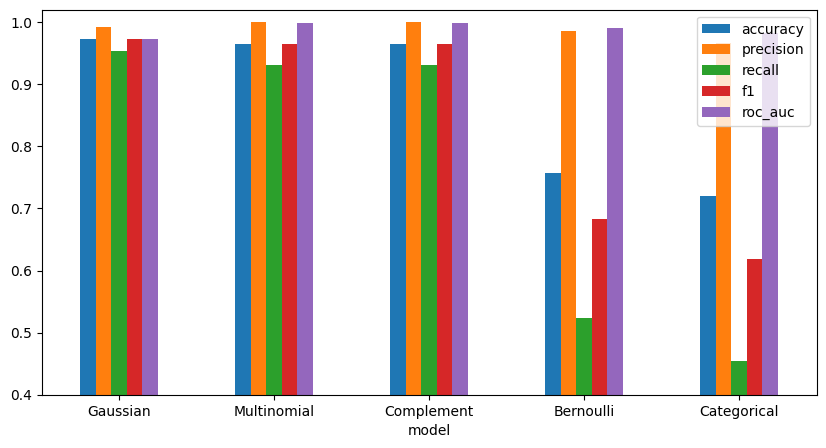

In [25]:
results_df.plot.bar(figsize=(10, 5), ylim=(0.4, 1.02), rot=0)

### Results

- gaussian gets the best accuracy and f1 (0.973), it misses less spam than the others but also lets 1 ham go to spam
- multinomial and complement are the same here, makes sense since the classes are balanced (130 / 130). precision is 1.0 so no ham is marked as spam, which is what you want for a spam filter
- they also have the best roc auc (0.998) so their probabilities rank mails better than gaussian, the 0.5 threshold is just a bit strict for spam
- bernoulli and categorical are much worse, recall is around 0.5 so they miss half the spam. bernoulli throws away the counts, and categorical treats every count as a separate label so it doesnt know 5 is more than 4
